# 05 - Baseline & Non-Graph Model Training and Honest Evaluation

**Purpose:** Train and compare non-graph tabular models against heuristic baselines under an honest protocol:
- **B0:** Random ranking (expected PR-AUC = base rate)
- **B1:** Rank by `n_prior_adv` (ties broken by `log_dependents`) - primary baseline
- **B2:** Rank by `log_dependents` (popularity only)
- **B3:** Rank by `n_prior_adv_365d` (recency only)
- **M1:** Logistic Regression (L2) on tabular features with Preprocessor
- **M2:** LightGBM on tabular features
- **M3:** LightGBM on tabular plus neighbour aggregation features
- **C1:** Control: M3 on degree-preserving shuffled graph

**Evaluation:** Evaluated on validation dates across All Packages and First-Time Subset (`had_prior_advisory == False`).
Primary selection metric: mean validation `lift@500` on the first-time subset; ties broken by mean `precision@100`.


In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'ml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data'; PROC = DATA / 'processed'; INTERIM = DATA / 'interim'
FIG = ROOT / 'docs' / 'figures' / 'baselines'; FIG.mkdir(parents=True, exist_ok=True)
T0 = time.time(); print('Project root:', ROOT)


Project root: D:\DepRadar


In [2]:
RUN_TEST = False          # leave False until the candidate is frozen (Part G); set True ONCE
ALLOW_RELOOK = False      # True only to repeat a test look; it is then logged as a re-look
HORIZON_MONTHS = 6
SEED = 0
B0_DRAWS = 20
LR_GRID = {"C": [0.01, 0.1, 1.0, 10.0], "class_weight": [None, "balanced"]}
LGBM_GRID = [dict(num_leaves=nl, learning_rate=lr, spw=spw)
             for nl in (15, 31) for lr in (0.03, 0.1) for spw in ("none", "sqrt")]   # 8 configs
LGBM_FIXED = dict(min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  n_estimators=2000, early_stopping_rounds=100)
FINAL_SEEDS = (0, 1, 2)
GATE_MIN_MEAN_DIFF = 0.0


In [3]:
import platform, sklearn, lightgbm, scipy, numpy as np, pandas as pd

print("Library versions:")
print(f"  Python: {platform.python_version()}, Pandas: {pd.__version__}, Numpy: {np.__version__}")
print(f"  Scikit-Learn: {sklearn.__version__}, LightGBM: {lightgbm.__version__}, Scipy: {scipy.__version__}")

grid_path = INTERIM / 'snapshot_grid.parquet'
if not grid_path.exists():
    grid_path = DATA / 'raw' / 'deps_dev' / 'snapshot_grid.parquet'
if not grid_path.exists():
    raise RuntimeError("PREFLIGHT FAILED: Snapshot grid missing (run pipelines/dataset_pipeline.py)")

grid = pd.read_parquet(grid_path)
missing_folders = []
train_val_dates = grid[grid['target_month'].between('2023-01', '2024-01') | grid['target_month'].between('2024-07', '2024-09')]['T'].dt.strftime('%Y-%m-%d')
for d_str in train_val_dates:
    f_dir = PROC / f"T={d_str}"
    for req_f in ['nodes.parquet', 'edges.parquet', 'features.parquet', 'labels.parquet']:
        if not (f_dir / req_f).exists():
            missing_folders.append(f"{f_dir.name}/{req_f} (stage: build_snapshots.py)")

test_dates = grid[grid['target_month'].between('2025-03', '2025-05') | grid['target_month'].between('2025-11', '2026-04')]['T'].dt.strftime('%Y-%m-%d')
proc_names = {f.name for f in PROC.iterdir() if f.is_dir()} if PROC.exists() else set()
for d_str in test_dates:
    if f"T={d_str}" not in proc_names:
        missing_folders.append(f"Test folder T={d_str} missing (stage: build_snapshots.py)")

if missing_folders:
    raise RuntimeError("PREFLIGHT FAILED:\n" + "\n".join(missing_folders[:5]))
print(f"Preflight passed: Grid loaded ({len(grid)} rows), snapshot folders verified.")


Library versions:
  Python: 3.11.17, Pandas: 3.0.6, Numpy: 2.4.6
  Scikit-Learn: 1.9.1, LightGBM: 4.7.0, Scipy: 1.17.1
Preflight passed: Grid loaded (41 rows), snapshot folders verified.


In [4]:
import numpy as np, pandas as pd

class Preprocessor:
    """Fit on the TRAIN split only; transform any split with the stored statistics.
    Steps: log1p on chosen columns (negatives clipped to 0) -> missing-flag columns (fixed at fit) -> median impute -> standardise."""
    def __init__(self, numeric, log1p_cols=()):
        self.numeric = list(numeric); self.log1p_cols = set(log1p_cols)

    def _base(self, df):
        X = df[self.numeric].astype(float).copy()
        for c in self.log1p_cols & set(self.numeric):
            X[c] = np.log1p(X[c].clip(lower=0))
        return X

    def fit(self, df):
        X = self._base(df)
        self.flag_cols_ = [c for c in self.numeric if X[c].isna().any()]
        self.median_ = X.median()
        Xf = X.fillna(self.median_)
        self.mean_ = Xf.mean()
        self.std_ = Xf.std(ddof=0).replace(0, 1.0).fillna(1.0)
        return self

    def transform(self, df):
        X = self._base(df)
        flags = pd.DataFrame({c + "_missing": X[c].isna().astype(float) for c in self.flag_cols_}, index=X.index)
        X = (X.fillna(self.median_) - self.mean_) / self.std_
        return pd.concat([X, flags], axis=1)


In [5]:
import numpy as np, pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

KS = (100, 500)

def rank_order(score, seed=0):
    """Indices from highest to lowest score; ties are broken by a seeded random key (never by package order)."""
    score = np.asarray(score, float)
    key = np.random.default_rng(seed).random(len(score))
    return np.lexsort((key, -np.nan_to_num(score, nan=-np.inf)))

def topk_metrics(score, y, ks=KS, seed=0):
    """precision@k, recall@k and lift@k (= precision@k / base rate). k is cut to the number of rows."""
    y = np.asarray(y).astype(int); n = len(y); pos = int(y.sum())
    base = pos / n if n else float("nan")
    order = rank_order(score, seed)
    out = {}
    for k in ks:
        ke = min(k, n)
        hits = int(y[order[:ke]].sum()) if ke else 0
        p = hits / ke if ke else float("nan")
        out[f"precision@{k}"] = p
        out[f"recall@{k}"] = hits / pos if pos else float("nan")
        out[f"lift@{k}"] = p / base if base and base > 0 else float("nan")
    return out

def reliability(prob, y, bins=10):
    """Equal-count (quantile) bins, because probabilities are small. Returns a DataFrame and the expected calibration error."""
    prob = np.asarray(prob, float); y = np.asarray(y).astype(float)
    df = pd.DataFrame({"p": prob, "y": y})
    df["bin"] = pd.qcut(df["p"].rank(method="first"), bins, labels=False, duplicates="drop")
    t = df.groupby("bin").agg(mean_pred=("p", "mean"), frac_pos=("y", "mean"), count=("y", "size")).reset_index(drop=True)
    ece = float((t["count"] / t["count"].sum() * (t["mean_pred"] - t["frac_pos"]).abs()).sum())
    return t, ece

def metrics_for_date(score, y, prob=None, seed=0):
    """One date, one population. `prob` (calibrated probabilities) is optional; rank-only baselines have none."""
    y = np.asarray(y).astype(int); n = len(y); pos = int(y.sum())
    m = {"n": n, "n_pos": pos, "base_rate": pos / n if n else float("nan")}
    ok = 0 < pos < n
    m["pr_auc"] = float(average_precision_score(y, score)) if ok else float("nan")
    m["roc_auc"] = float(roc_auc_score(y, score)) if ok else float("nan")
    m.update(topk_metrics(score, y, seed=seed))
    if prob is not None and n:
        m["brier"] = float(brier_score_loss(y, prob)); m["ece"] = reliability(prob, y)[1]
    return m

def shuffle_edges_keep_degrees(src, dst, seed=0):
    """Permute the destination column. Every node keeps its out-degree and its in-degree; only who links to whom changes.
    Self-loops and duplicate edges created by the shuffle are removed (counts returned)."""
    src, dst = np.asarray(src), np.asarray(dst)
    d = np.random.default_rng(seed).permutation(dst)
    keep = src != d
    e = pd.DataFrame({"s": src[keep], "d": d[keep]})
    n_before = len(e); e = e.drop_duplicates()
    return e["s"].to_numpy(), e["d"].to_numpy(), {"self_loops_removed": int((~keep).sum()), "duplicates_removed": int(n_before - len(e))}

def nb_mean_max(n, src, dst, value):
    """Mean and max of `value` over each node's out-neighbours (dependencies) and in-neighbours (dependents).
    Nodes without neighbours get NaN. Edge src -> dst means src depends on dst."""
    value = np.asarray(value, float)
    res = {}
    for name, a, b in (("out", src, dst), ("in", dst, src)):
        g = pd.DataFrame({"i": a, "v": value[b]}).groupby("i")["v"]
        res[f"{name}_mean"] = g.mean().reindex(range(n)).to_numpy()
        res[f"{name}_max"] = g.max().reindex(range(n)).to_numpy()
    return res


In [6]:
import pandas as pd
SPLIT_MONTHS = {"train": ("2023-01", "2024-01"), "val": ("2024-07", "2024-09"),
                "test_a": ("2025-03", "2025-05"), "test_b": ("2025-11", "2026-04")}

def assign_splits(grid, split_months=SPLIT_MONTHS):
    g = grid.copy(); g["split"] = None
    for name, (a, b) in split_months.items():
        g.loc[(g.target_month >= a) & (g.target_month <= b), "split"] = name
    return g[g.split.notna()].reset_index(drop=True)

def apply_embargo(g, order=("train", "val", "test_a", "test_b"), horizon=HORIZON_MONTHS):
    g = g.copy(); dropped = []
    for prev, nxt in zip(order, order[1:]):
        if not (g.split == prev).any() or not (g.split == nxt).any():
            continue
        limit = (g.loc[g.split == prev, "T"].max() + pd.DateOffset(months=horizon)).date()
        while (g.split == nxt).any() and g.loc[g.split == nxt, "T"].min().date() <= limit:
            idx = g.loc[g.split == nxt, "T"].idxmin()
            dropped.append(g.loc[idx, "T"]); g = g.drop(idx)
    return g.reset_index(drop=True), dropped

RESULTS = []
def check(name, ok, detail=""):
    RESULTS.append((name, bool(ok), detail))
    print(("PASS " if ok else "FAIL "), name, ("| " + str(detail)) if detail else "")


## Part A - Data and Preparation

**Question:** Are train and validation splits embargo-separated, feature matrices properly aligned, and preprocessors strictly fitted on train rows?
**How to read:** Summary tables show positive counts and base rates across dates. Property assertions verify data integrity and absence of test split exposure.


In [7]:
# Build splits and apply horizon embargo
labelled_grid = assign_splits(grid[~grid['is_now']])
grid2, dropped_dates = apply_embargo(labelled_grid)

train_grid = grid2[grid2['split'] == 'train'].reset_index(drop=True)
val_grid = grid2[grid2['split'] == 'val'].reset_index(drop=True)
train_dates = train_grid['T'].dt.date.astype(str).tolist()
val_dates = val_grid['T'].dt.date.astype(str).tolist()

print(f"Splits: train={len(train_dates)} dates, val={len(val_dates)} dates.")
print(f"Dropped embargo dates: {[str(d.date()) for d in dropped_dates]}")

# Verify embargo separation
order = ("train", "val", "test_a", "test_b")
embargo_ok = True
for prev, nxt in zip(order, order[1:]):
    if (grid2.split == prev).any() and (grid2.split == nxt).any():
        p_max = grid2.loc[grid2.split == prev, 'T'].max()
        n_min = grid2.loc[grid2.split == nxt, 'T'].min()
        if n_min.date() <= (p_max + pd.DateOffset(months=HORIZON_MONTHS)).date():
            embargo_ok = False
check("embargo separation: consecutive splits strictly separated by > horizon months", embargo_ok)


Splits: train=13 dates, val=2 dates.
Dropped embargo dates: ['2024-07-01']
PASS  embargo separation: consecutive splits strictly separated by > horizon months 


In [8]:
# Track all opened parquet paths for test-protection verification
OPENED_FILES = []

def load_date(d_str):
    folder = PROC / f"T={d_str}"
    f_path, l_path, e_path = folder / 'features.parquet', folder / 'labels.parquet', folder / 'edges.parquet'
    OPENED_FILES.extend([f_path, l_path, e_path])
    
    feats = pd.read_parquet(f_path)
    lbls = pd.read_parquet(l_path)
    edges = pd.read_parquet(e_path)
    
    assert (feats['idx'].values == lbls['idx'].values).all(), f"Row alignment failed at {d_str}"
    merged = pd.concat([feats, lbls[['label', 'had_prior_advisory', 'n_adv_in_window']]], axis=1)
    return merged, edges['src'].values, edges['dst'].values

X, E = {}, {}
for d in train_dates + val_dates:
    df_d, src_d, dst_d = load_date(d)
    X[d], E[d] = df_d, (src_d, dst_d)

print(f"Loaded {len(train_dates)} train dates and {len(val_dates)} val dates into memory.")


Loaded 13 train dates and 2 val dates into memory.


In [9]:
# Table per train and val date
date_summary_rows = []
all_pos_ge_30 = True

for split_name, d_list in [('train', train_dates), ('val', val_dates)]:
    for d in d_list:
        df_d = X[d]
        n_tot, n_pos = len(df_d), int(df_d['label'].sum())
        if n_pos < 30: all_pos_ge_30 = False
        
        ft_m = (df_d['had_prior_advisory'] == False)
        n_ft, n_ft_pos = int(ft_m.sum()), int(df_d.loc[ft_m, 'label'].sum())
        prior_m = (df_d['had_prior_advisory'] == True)
        p_prior_rate = float(df_d.loc[prior_m, 'label'].mean()) if prior_m.sum() > 0 else np.nan
        
        date_summary_rows.append({
            'split': split_name, 'date': d, 'packages': n_tot, 'positives': n_pos,
            'base_rate': n_pos / n_tot, 'first_time_pkgs': n_ft, 'first_time_pos': n_ft_pos,
            'first_time_base_rate': n_ft_pos / n_ft if n_ft else np.nan,
            'prior_pos_rate': p_prior_rate
        })

df_date_summary = pd.DataFrame(date_summary_rows)
check("all-packages positives >= 30 for every train and val date", all_pos_ge_30)
print("Per-date summary table (head and tail):\n", pd.concat([df_date_summary.head(3), df_date_summary.tail(3)]).to_string(index=False))


PASS  all-packages positives >= 30 for every train and val date 
Per-date summary table (head and tail):
 split       date  packages  positives  base_rate  first_time_pkgs  first_time_pos  first_time_base_rate  prior_pos_rate
train 2023-01-02     30000         95   0.003167            29234              52              0.001779        0.056136
train 2023-01-29     30000         90   0.003000            29227              50              0.001711        0.051746
train 2023-02-27     30000         80   0.002667            29214              43              0.001472        0.047074
train 2024-01-01     30000         79   0.002633            29142              39              0.001338        0.046620
  val 2024-07-29     30000         75   0.002500            29208              37              0.001267        0.047980
  val 2024-09-02     30000         81   0.002700            29206              46              0.001575        0.044081


In [10]:
import json

# Resolve feature sets from audit summary or fallback
audit_file = INTERIM / 'feature_audit_summary.json'
if audit_file.exists():
    with open(audit_file) as f:
        aud = json.load(f)
    FEATURES_M1_M2 = aud['feature_sets']['FEATURES_M1_M2']
    FEATURES_M3 = aud['feature_sets']['FEATURES_M3']
    LOG1P_COLS = aud['preprocessing']['log1p_cols']
    print(f"Loaded features from audit summary: M1/M2={len(FEATURES_M1_M2)}, M3={len(FEATURES_M3)}")
else:
    fallback_nongraph = ['age_days', 'n_versions', 'n_release_versions', 'days_since_last_release',
                         'median_gap_days_last20', 'n_deps_prod', 'log_dependents', 'dependents_delta_3m',
                         'n_prior_adv', 'days_since_last_adv', 'has_prior_adv', 'max_severity_ord', 'n_prior_critical_high']
    fallback_graph = ['out_deg', 'in_deg', 'nb_out_mean_prior_adv', 'nb_out_max_prior_adv', 'nb_out_frac_prior_adv',
                      'nb_in_mean_prior_adv', 'nb_in_max_prior_adv', 'nb_in_frac_prior_adv',
                      'nb_out_mean_log_dependents', 'nb_in_mean_log_dependents']
    FEATURES_M1_M2 = [c for c in fallback_nongraph if c in X[train_dates[0]].columns]
    FEATURES_M3 = FEATURES_M1_M2 + [c for c in fallback_graph if c in X[train_dates[0]].columns]
    LOG1P_COLS = ['n_versions', 'n_release_versions', 'n_deps_prod', 'n_prior_adv']
    print("Used fallback feature sets.")

forbidden = {'package', 'idx', 'label', 'had_prior_advisory', 'n_adv_in_window'}
check("feature lists contain zero forbidden label or index columns", len(set(FEATURES_M3) & forbidden) == 0)

# Pool train rows and fit Preprocessor (for M1)
df_train_pooled = pd.concat([X[d] for d in train_dates], ignore_index=True)
assert len(set(train_dates) & set(val_dates)) == 0, "Train and val dates must be disjoint"
assert all(c in df_train_pooled.columns for c in FEATURES_M3), "Every feature column must exist"
inf_cnt = sum(np.isinf(X[d][FEATURES_M3].select_dtypes(include=np.number)).sum().sum() for d in train_dates)
print(f"+/-inf count in train features: {inf_cnt}")
assert inf_cnt == 0, "No feature value may be +/-inf"
check("feature assertions: columns exist, no +/-inf, disjoint dates", inf_cnt == 0)

prep = Preprocessor(numeric=FEATURES_M1_M2, log1p_cols=LOG1P_COLS).fit(df_train_pooled)
check("preprocessor fitted strictly on pooled train rows", len(df_train_pooled) == sum(len(X[d]) for d in train_dates))
print(f"Preprocessor fitted on {len(df_train_pooled):,} rows. Flag columns: {len(prep.flag_cols_)}")


Loaded features from audit summary: M1/M2=13, M3=23
PASS  feature lists contain zero forbidden label or index columns 
+/-inf count in train features: 0
PASS  feature assertions: columns exist, no +/-inf, disjoint dates 
PASS  preprocessor fitted strictly on pooled train rows 
Preprocessor fitted on 390,000 rows. Flag columns: 5


## Part B - Baselines B0-B3 (No Training)

**Question:** How do heuristic baselines (Random, Advisory History, Popularity, Recency) perform across validation dates?
**How to read:** Tables report mean and standard deviation across validation dates for All Packages and First-Time Subset. Metrics include PR-AUC, precision@k, recall@k, and lift@k.


In [11]:
# B0: Random ranking (mean over B0_DRAWS seeded draws)
baseline_val_records = []

for d in val_dates:
    df_d = X[d]
    y_all = df_d['label'].values
    ft_mask = (df_d['had_prior_advisory'] == False).values
    
    b0_all_list, b0_ft_list = [], []
    for s_idx in range(B0_DRAWS):
        rng = np.random.default_rng(SEED + s_idx)
        rnd_s = rng.random(len(df_d))
        b0_all_list.append(metrics_for_date(rnd_s, y_all, seed=SEED + s_idx))
        b0_ft_list.append(metrics_for_date(rnd_s[ft_mask], y_all[ft_mask], seed=SEED + s_idx))
    
    b0_all = pd.DataFrame(b0_all_list).mean().to_dict()
    b0_ft = pd.DataFrame(b0_ft_list).mean().to_dict()
    baseline_val_records.append({'model': 'B0', 'date': d, 'pop': 'all', **b0_all})
    baseline_val_records.append({'model': 'B0', 'date': d, 'pop': 'first_time', **b0_ft})

print(f"B0 computed across {len(val_dates)} validation dates with {B0_DRAWS} draws per date.")


B0 computed across 2 validation dates with 20 draws per date.


In [12]:
from scipy.stats import rankdata

b1_b2_diffs = []
for d in val_dates:
    df_d = X[d]
    y_all = df_d['label'].values
    ft_mask = (df_d['had_prior_advisory'] == False).values
    
    # B1: n_prior_adv + scaled rank of log_dependents
    rank_dep = (rankdata(df_d['log_dependents'].values) - 1.0) / len(df_d)
    score_b1 = df_d['n_prior_adv'].values + rank_dep
    baseline_val_records.append({'model': 'B1', 'date': d, 'pop': 'all', **metrics_for_date(score_b1, y_all, seed=SEED)})
    m_b1_ft = metrics_for_date(score_b1[ft_mask], y_all[ft_mask], seed=SEED)
    baseline_val_records.append({'model': 'B1', 'date': d, 'pop': 'first_time', **m_b1_ft})
    
    # B2: log_dependents
    score_b2 = df_d['log_dependents'].values
    baseline_val_records.append({'model': 'B2', 'date': d, 'pop': 'all', **metrics_for_date(score_b2, y_all, seed=SEED)})
    m_b2_ft = metrics_for_date(score_b2[ft_mask], y_all[ft_mask], seed=SEED)
    baseline_val_records.append({'model': 'B2', 'date': d, 'pop': 'first_time', **m_b2_ft})
    b1_b2_diffs.append(abs(m_b1_ft['lift@500'] - m_b2_ft['lift@500']))
    
    # B3: n_prior_adv_365d
    score_b3 = df_d['n_prior_adv_365d'].values
    baseline_val_records.append({'model': 'B3', 'date': d, 'pop': 'all', **metrics_for_date(score_b3, y_all, seed=SEED)})
    baseline_val_records.append({'model': 'B3', 'date': d, 'pop': 'first_time', **metrics_for_date(score_b3[ft_mask], y_all[ft_mask], seed=SEED)})

print(f"B1 vs B2 on first-time subset: max absolute difference in lift@500 = {max(b1_b2_diffs):.6f}")


B1 vs B2 on first-time subset: max absolute difference in lift@500 = 0.000000


In [13]:
# Summarise baseline performance across validation dates
df_b_records = pd.DataFrame(baseline_val_records)
df_b_summary = df_b_records.groupby(['model', 'pop']).agg({
    'base_rate': ['mean'], 'pr_auc': ['mean', 'std'], 'roc_auc': ['mean', 'std'],
    'precision@100': ['mean', 'std'], 'lift@100': ['mean', 'std'],
    'precision@500': ['mean', 'std'], 'lift@500': ['mean', 'std'], 'recall@500': ['mean', 'std']
}).reset_index()

df_b_summary.columns = ['_'.join(c).strip('_') for c in df_b_summary.columns]
print("Baseline validation performance summary:\n", df_b_summary.to_string(index=False))

b0_all_row = df_b_records[(df_b_records['model'] == 'B0') & (df_b_records['pop'] == 'all')]
b0_ft_row = df_b_records[(df_b_records['model'] == 'B0') & (df_b_records['pop'] == 'first_time')]
b0_err_all = abs(b0_all_row['pr_auc'].mean() - b0_all_row['base_rate'].mean()) / b0_all_row['base_rate'].mean()
b0_err_ft = abs(b0_ft_row['pr_auc'].mean() - b0_ft_row['base_rate'].mean()) / b0_ft_row['base_rate'].mean()
check("B0 expected PR-AUC within 30% of base rate for both populations", (b0_err_all < 0.30) and (b0_err_ft < 0.30),
      detail=f"all={b0_err_all:.4f}, ft={b0_err_ft:.4f}")


Baseline validation performance summary:
 model        pop  base_rate_mean  pr_auc_mean  pr_auc_std  roc_auc_mean  roc_auc_std  precision@100_mean  precision@100_std  lift@100_mean  lift@100_std  precision@500_mean  precision@500_std  lift@500_mean  lift@500_std  recall@500_mean  recall@500_std
   B0        all        0.002600     0.002940    0.000235      0.495252     0.005005             0.00325           0.001768       1.270370      0.749009              0.0028           0.000849       1.087407      0.385504         0.018123        0.006425
   B0 first_time        0.001421     0.001831    0.000314      0.498513     0.015788             0.00125           0.001061       0.948134      0.891912              0.0015           0.000566       1.099137      0.566722         0.018816        0.009701
   B1        all        0.002600     0.091173    0.003189      0.824474     0.018279             0.14500           0.007071      55.777778      0.314270              0.0610           0.001414     

## Part C - M1 Logistic Regression (L2)

**Question:** How does a regularized linear model on standardized tabular features perform, and which features carry the largest coefficients?
**How to read:** Hyper-parameter selection grid table over validation dates. Diagnostic table reports validation performance, calibration ECE, and top standardized coefficients.


In [14]:
from sklearn.linear_model import LogisticRegression

# Prepare transformed train and val sets for M1
X_tr_m1 = prep.transform(df_train_pooled)
y_tr_m1 = df_train_pooled['label'].values
X_val_m1 = {d: prep.transform(X[d]) for d in val_dates}
lr_grid_results = []

for c_val in LR_GRID['C']:
    for cw in LR_GRID['class_weight']:
        lr = LogisticRegression(penalty='l2', C=c_val, class_weight=cw, solver='lbfgs', max_iter=1000, random_state=SEED)
        lr.fit(X_tr_m1, y_tr_m1)
        
        val_l500, val_p100, val_prauc = [], [], []
        for d in val_dates:
            df_d = X[d]
            s_d = lr.predict_proba(X_val_m1[d])[:, 1]
            ft_m = (df_d['had_prior_advisory'] == False).values
            m_ft = topk_metrics(s_d[ft_m], df_d.loc[ft_m, 'label'], ks=(100, 500), seed=SEED)
            val_l500.append(m_ft['lift@500']); val_p100.append(m_ft['precision@100'])
            val_prauc.append(average_precision_score(df_d['label'], s_d))
            
        lr_grid_results.append({
            'C': c_val, 'class_weight': str(cw),
            'primary_lift500_ft': np.mean(val_l500), 'prec100_ft': np.mean(val_p100),
            'secondary_prauc_all': np.mean(val_prauc), 'model_obj': lr
        })

df_lr_grid = pd.DataFrame(lr_grid_results).sort_values(by=['primary_lift500_ft', 'prec100_ft'], ascending=False)
best_lr_entry = df_lr_grid.iloc[0]
best_lr = best_lr_entry['model_obj']
print("M1 Logistic Regression Grid Results:\n", df_lr_grid[['C', 'class_weight', 'primary_lift500_ft', 'prec100_ft', 'secondary_prauc_all']].to_string(index=False))


c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\anaconda3\envs\depradar\Li

M1 Logistic Regression Grid Results:
     C class_weight  primary_lift500_ft  prec100_ft  secondary_prauc_all
 0.01     balanced           21.055792       0.045             0.116076
 0.10     balanced           21.055792       0.045             0.114688
10.00     balanced           19.631474       0.040             0.113925
 1.00     balanced           18.361647       0.040             0.113665
 0.01         None           17.572242       0.050             0.131229
 0.10         None           16.782837       0.055             0.130775
 1.00         None           16.782837       0.050             0.130701
10.00         None           16.782837       0.050             0.130720


In [15]:
# Evaluate best M1 model across validation dates
m1_val_records = []
m1_pooled_prob, m1_pooled_y = [], []

for d in val_dates:
    df_d = X[d]
    y_d = df_d['label'].values
    prob_d = best_lr.predict_proba(X_val_m1[d])[:, 1]
    ft_m = (df_d['had_prior_advisory'] == False).values
    
    m1_val_records.append({'model': 'M1', 'date': d, 'pop': 'all', **metrics_for_date(prob_d, y_d, prob=prob_d, seed=SEED)})
    m1_val_records.append({'model': 'M1', 'date': d, 'pop': 'first_time', **metrics_for_date(prob_d[ft_m], y_d[ft_m], prob=prob_d[ft_m], seed=SEED)})
    m1_pooled_prob.extend(prob_d); m1_pooled_y.extend(y_d)

rel_m1, ece_m1 = reliability(np.array(m1_pooled_prob), np.array(m1_pooled_y))
print(f"M1 Pooled Validation Calibration: ECE = {ece_m1:.4f}")
print("M1 Reliability Table (quantiles):\n", rel_m1.round(4).to_string(index=False))


M1 Pooled Validation Calibration: ECE = 0.2317
M1 Reliability Table (quantiles):
  mean_pred  frac_pos  count
    0.0069    0.0000   6000
    0.0095    0.0003   6000
    0.0227    0.0000   6000
    0.0914    0.0000   6000
    0.1447    0.0005   6000
    0.1952    0.0005   6000
    0.2620    0.0015   6000
    0.3595    0.0008   6000
    0.5035    0.0025   6000
    0.7476    0.0198   6000


In [16]:
# Top standardized coefficients for M1
coef_df = pd.DataFrame({
    'feature': X_tr_m1.columns,
    'coefficient': best_lr.coef_[0],
    'abs_coef': np.abs(best_lr.coef_[0])
}).sort_values(by='abs_coef', ascending=False)

print("Top 15 standardized coefficients for M1:\n", coef_df.head(15)[['feature', 'coefficient']].to_string(index=False))


Top 15 standardized coefficients for M1:
                         feature  coefficient
 median_gap_days_last20_missing    -1.640891
    dependents_delta_3m_missing     0.555802
                     n_versions     0.483769
            dependents_delta_3m     0.478891
    days_since_last_adv_missing    -0.446288
                  has_prior_adv     0.402832
                    n_prior_adv     0.232186
               max_severity_ord    -0.231442
        days_since_last_release    -0.202822
                       age_days     0.186668
                 log_dependents     0.135343
                    n_deps_prod     0.129226
             n_release_versions     0.114243
               age_days_missing    -0.101727
days_since_last_release_missing    -0.101727


## Part D - M2 LightGBM (Non-Graph Features)

**Question:** How does a gradient-boosted decision tree perform on non-graph tabular features, and which features drive gain importance?
**How to read:** Grid table over trees and learning rates with validation early stopping. Importance plots show relative feature gain.


In [17]:
# Prepare pooled training and validation matrices for M2
X_tr_m2 = df_train_pooled[FEATURES_M1_M2]
y_tr_m2 = df_train_pooled['label'].values
n_pos_tr = int(y_tr_m2.sum())
n_neg_tr = len(y_tr_m2) - n_pos_tr

df_val_pooled = pd.concat([X[d] for d in val_dates], ignore_index=True)
X_val_m2_pooled = df_val_pooled[FEATURES_M1_M2]
y_val_m2_pooled = df_val_pooled['label'].values

print(f"M2 training pool: {len(X_tr_m2):,} rows ({n_pos_tr} positive, {n_neg_tr} negative). Features: {len(FEATURES_M1_M2)}")


M2 training pool: 390,000 rows (1062 positive, 388938 negative). Features: 13


In [18]:
import lightgbm as lgb

m2_grid_results = []
for idx_cfg, cfg in enumerate(LGBM_GRID):
    spw_val = np.sqrt(n_neg_tr / n_pos_tr) if cfg['spw'] == 'sqrt' else 1.0
    clf = lgb.LGBMClassifier(
        objective='binary', n_estimators=LGBM_FIXED['n_estimators'],
        learning_rate=cfg['learning_rate'], num_leaves=cfg['num_leaves'],
        min_child_samples=LGBM_FIXED['min_child_samples'], subsample=LGBM_FIXED['subsample'],
        subsample_freq=LGBM_FIXED['subsample_freq'], colsample_bytree=LGBM_FIXED['colsample_bytree'],
        scale_pos_weight=spw_val, random_state=SEED, n_jobs=-1, verbose=-1
    )
    clf.fit(X_tr_m2, y_tr_m2, eval_set=[(X_val_m2_pooled, y_val_m2_pooled)],
            eval_metric='average_precision', callbacks=[lgb.early_stopping(LGBM_FIXED['early_stopping_rounds'], verbose=False)])
    
    val_l500, val_p100, val_pr = [], [], []
    for d in val_dates:
        df_d = X[d]
        s_d = clf.predict_proba(df_d[FEATURES_M1_M2])[:, 1]
        ft_m = (df_d['had_prior_advisory'] == False).values
        m_ft = topk_metrics(s_d[ft_m], df_d.loc[ft_m, 'label'], ks=(100, 500), seed=SEED)
        val_l500.append(m_ft['lift@500']); val_p100.append(m_ft['precision@100'])
        val_pr.append(average_precision_score(df_d['label'], s_d))
        
    m2_grid_results.append({
        'cfg_idx': idx_cfg, **cfg, 'best_iteration': clf.best_iteration_,
        'primary_lift500_ft': np.mean(val_l500), 'prec100_ft': np.mean(val_p100),
        'secondary_prauc_all': np.mean(val_pr)
    })
    print(f"M2 Config {idx_cfg+1}/8: lr={cfg['learning_rate']}, nl={cfg['num_leaves']}, spw={cfg['spw']} -> best_iter={clf.best_iteration_}, lift@500={np.mean(val_l500):.3f}")

df_m2_grid = pd.DataFrame(m2_grid_results).sort_values(by=['primary_lift500_ft', 'prec100_ft'], ascending=False)
best_m2_cfg = df_m2_grid.iloc[0].to_dict()
print("\nBest M2 configuration selected:\n", best_m2_cfg)


c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


M2 Config 1/8: lr=0.03, nl=15, spw=none -> best_iter=76, lift@500=9.026


c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


M2 Config 2/8: lr=0.03, nl=15, spw=sqrt -> best_iter=1, lift@500=6.332


c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

M2 Config 6/8: lr=0.03, nl=31, spw=sqrt -> best_iter=1, lift@500=5.388


c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


M2 Config 7/8: lr=0.1, nl=31, spw=none -> best_iter=10, lift@500=8.391


c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


M2 Config 8/8: lr=0.1, nl=31, spw=sqrt -> best_iter=1, lift@500=5.388

Best M2 configuration selected:
 {'cfg_idx': 4, 'num_leaves': 31, 'learning_rate': 0.03, 'spw': 'none', 'best_iteration': 73, 'primary_lift500_ft': 9.81573678025852, 'prec100_ft': 0.015, 'secondary_prauc_all': 0.0771653028761181}


In [19]:
# Retrain best M2 configuration with 3 seeds and average scores
m2_seed_models, m2_seed_l500 = [], []
spw_best = np.sqrt(n_neg_tr / n_pos_tr) if best_m2_cfg['spw'] == 'sqrt' else 1.0

for s in FINAL_SEEDS:
    m = lgb.LGBMClassifier(
        objective='binary', n_estimators=int(best_m2_cfg['best_iteration']),
        learning_rate=best_m2_cfg['learning_rate'], num_leaves=int(best_m2_cfg['num_leaves']),
        min_child_samples=LGBM_FIXED['min_child_samples'], subsample=LGBM_FIXED['subsample'],
        subsample_freq=LGBM_FIXED['subsample_freq'], colsample_bytree=LGBM_FIXED['colsample_bytree'],
        scale_pos_weight=spw_best, random_state=s, n_jobs=-1, verbose=-1
    ).fit(X_tr_m2, y_tr_m2)
    m2_seed_models.append(m)
    s_l = [topk_metrics(m.predict_proba(X[d][FEATURES_M1_M2])[:, 1][(X[d]['had_prior_advisory'] == False).values],
                        X[d].loc[(X[d]['had_prior_advisory'] == False).values, 'label'], ks=(500,), seed=SEED)['lift@500'] for d in val_dates]
    m2_seed_l500.append(np.mean(s_l))

print(f"M2 single-seed validation lift@500 (ft): {[round(x, 3) for x in m2_seed_l500]} -> mean={np.mean(m2_seed_l500):.3f} +/- {np.std(m2_seed_l500):.3f}")

m2_val_records = []
m2_pooled_prob, m2_pooled_y = [], []
for d in val_dates:
    df_d, y_d = X[d], X[d]['label'].values
    prob_seeds = np.mean([m.predict_proba(df_d[FEATURES_M1_M2])[:, 1] for m in m2_seed_models], axis=0)
    ft_m = (df_d['had_prior_advisory'] == False).values
    m2_val_records.append({'model': 'M2', 'date': d, 'pop': 'all', **metrics_for_date(prob_seeds, y_d, prob=prob_seeds, seed=SEED)})
    m2_val_records.append({'model': 'M2', 'date': d, 'pop': 'first_time', **metrics_for_date(prob_seeds[ft_m], y_d[ft_m], prob=prob_seeds[ft_m], seed=SEED)})
    m2_pooled_prob.extend(prob_seeds); m2_pooled_y.extend(y_d)

rel_m2, ece_m2 = reliability(np.array(m2_pooled_prob), np.array(m2_pooled_y))
print(f"M2 Seed-Averaged Calibration ECE = {ece_m2:.4f}")


M2 single-seed validation lift@500 (ft): [np.float64(9.816), np.float64(6.332), np.float64(6.967)] -> mean=7.705 +/- 1.515
M2 Seed-Averaged Calibration ECE = 0.0005


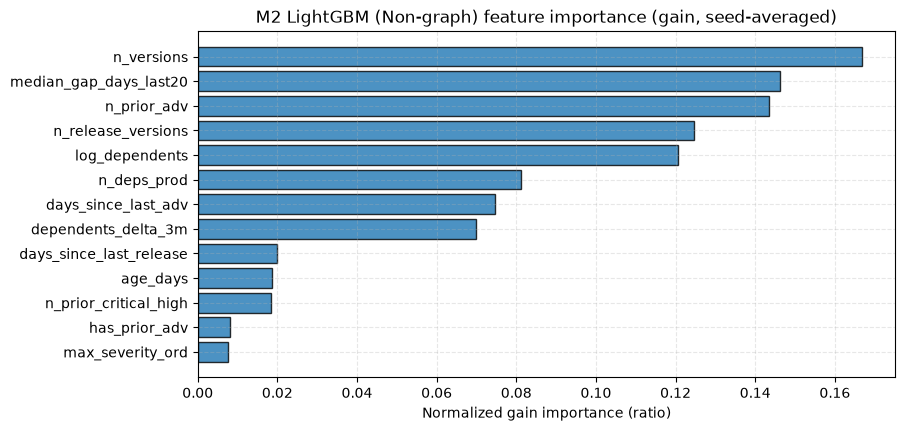

Top 10 M2 features by gain importance:
                 feature  importance
             n_versions    0.166817
 median_gap_days_last20    0.146223
            n_prior_adv    0.143414
     n_release_versions    0.124633
         log_dependents    0.120510
            n_deps_prod    0.081266
    days_since_last_adv    0.074621
    dependents_delta_3m    0.069945
days_since_last_release    0.019822
               age_days    0.018675


In [20]:
import matplotlib.pyplot as plt

# Feature importance: Normalized gain importance averaged across seeds
m2_importances = np.mean([m.booster_.feature_importance(importance_type='gain') for m in m2_seed_models], axis=0)
df_m2_imp = pd.DataFrame({'feature': FEATURES_M1_M2, 'importance': m2_importances / m2_importances.sum()}).sort_values(by='importance', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
top20_m2 = df_m2_imp.head(20).iloc[::-1]
ax.barh(top20_m2['feature'], top20_m2['importance'], color='#1f77b4', edgecolor='black', alpha=0.8)
ax.set_xlabel('Normalized gain importance (ratio)')
ax.set_title('M2 LightGBM (Non-graph) feature importance (gain, seed-averaged)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_01_m2_feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()

print("Top 10 M2 features by gain importance:\n", df_m2_imp.head(10).to_string(index=False))


## Part E - M3 and the Shuffled-Graph Control C1

**Question:** Does adding topological neighbour aggregates (M3) improve performance, and does real graph structure matter over degree-preserving shuffled controls (C1)?
**How to read:** Tables display neighbour aggregation reproducibility, hyper-parameter selection, and paired comparisons of M3 versus C1.


In [21]:
# Verify exact reproduction of neighbour features from edges
chk_d = train_dates[0]
df_chk, src_chk, dst_chk = X[chk_d], E[chk_d][0], E[chk_d][1]
n_chk = len(df_chk)
nb_reproduce_rows = []

# Prior adv aggregates
res_adv = nb_mean_max(n_chk, src_chk, dst_chk, df_chk['n_prior_adv'].values)
for stat in ['mean', 'max']:
    for direction in ['out', 'in']:
        col = f"nb_{direction}_{stat}_prior_adv"
        match = np.isclose(df_chk[col], np.nan_to_num(res_adv[f"{direction}_{stat}"], nan=0.0), atol=1e-6).mean()
        nb_reproduce_rows.append({'feature': col, 'candidate': 'n_prior_adv', 'convention': '0', 'match_rate': match})

# Frac prior aggregates
res_frac = nb_mean_max(n_chk, src_chk, dst_chk, df_chk['has_prior_adv'].values)
for direction in ['out', 'in']:
    col = f"nb_{direction}_frac_prior_adv"
    match = np.isclose(df_chk[col], np.nan_to_num(res_frac[f"{direction}_mean"], nan=0.0), atol=1e-6).mean()
    nb_reproduce_rows.append({'feature': col, 'candidate': 'has_prior_adv (mean)', 'convention': '0', 'match_rate': match})

# Mean log_dependents aggregates
res_dep = nb_mean_max(n_chk, src_chk, dst_chk, df_chk['log_dependents'].values)
for direction in ['out', 'in']:
    col = f"nb_{direction}_mean_log_dependents"
    match = np.isclose(df_chk[col], np.nan_to_num(res_dep[f"{direction}_mean"], nan=0.0), atol=1e-6).mean()
    nb_reproduce_rows.append({'feature': col, 'candidate': 'log_dependents', 'convention': '0', 'match_rate': match})

df_nb_reprod = pd.DataFrame(nb_reproduce_rows)
check("all neighbour features reproduced within 1e-6 for >= 99.99% of nodes", (df_nb_reprod['match_rate'] >= 0.9999).all())
print("Neighbour feature reproduction audit:\n", df_nb_reprod.to_string(index=False))


PASS  all neighbour features reproduced within 1e-6 for >= 99.99% of nodes 
Neighbour feature reproduction audit:
                    feature            candidate convention  match_rate
     nb_out_mean_prior_adv          n_prior_adv          0         1.0
      nb_in_mean_prior_adv          n_prior_adv          0         1.0
      nb_out_max_prior_adv          n_prior_adv          0         1.0
       nb_in_max_prior_adv          n_prior_adv          0         1.0
     nb_out_frac_prior_adv has_prior_adv (mean)          0         1.0
      nb_in_frac_prior_adv has_prior_adv (mean)          0         1.0
nb_out_mean_log_dependents       log_dependents          0         1.0
 nb_in_mean_log_dependents       log_dependents          0         1.0


In [22]:
# Train M3 LightGBM with graph neighbour features
X_tr_m3 = df_train_pooled[FEATURES_M3]
X_val_m3_pooled = df_val_pooled[FEATURES_M3]

m3_grid_results = []
for idx_cfg, cfg in enumerate(LGBM_GRID):
    spw_val = np.sqrt(n_neg_tr / n_pos_tr) if cfg['spw'] == 'sqrt' else 1.0
    clf = lgb.LGBMClassifier(
        objective='binary', n_estimators=LGBM_FIXED['n_estimators'],
        learning_rate=cfg['learning_rate'], num_leaves=cfg['num_leaves'],
        min_child_samples=LGBM_FIXED['min_child_samples'], subsample=LGBM_FIXED['subsample'],
        subsample_freq=LGBM_FIXED['subsample_freq'], colsample_bytree=LGBM_FIXED['colsample_bytree'],
        scale_pos_weight=spw_val, random_state=SEED, n_jobs=-1, verbose=-1
    )
    clf.fit(X_tr_m3, y_tr_m2, eval_set=[(X_val_m3_pooled, y_val_m2_pooled)],
            eval_metric='average_precision', callbacks=[lgb.early_stopping(LGBM_FIXED['early_stopping_rounds'], verbose=False)])
    
    val_l500, val_p100 = [], []
    for d in val_dates:
        s_d = clf.predict_proba(X[d][FEATURES_M3])[:, 1]
        ft_m = (X[d]['had_prior_advisory'] == False).values
        m_ft = topk_metrics(s_d[ft_m], X[d].loc[ft_m, 'label'], ks=(100, 500), seed=SEED)
        val_l500.append(m_ft['lift@500']); val_p100.append(m_ft['precision@100'])
        
    m3_grid_results.append({
        'cfg_idx': idx_cfg, **cfg, 'best_iteration': clf.best_iteration_,
        'primary_lift500_ft': np.mean(val_l500), 'prec100_ft': np.mean(val_p100)
    })

df_m3_grid = pd.DataFrame(m3_grid_results).sort_values(by=['primary_lift500_ft', 'prec100_ft'], ascending=False)
best_m3_cfg = df_m3_grid.iloc[0].to_dict()
print("Best M3 configuration selected:\n", best_m3_cfg)


c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\HP\anaconda3\envs\depradar\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(e

Best M3 configuration selected:
 {'cfg_idx': 1, 'num_leaves': 15, 'learning_rate': 0.03, 'spw': 'sqrt', 'best_iteration': 1, 'primary_lift500_ft': 13.299286721504114, 'prec100_ft': 0.025}


In [23]:
# Retrain M3 with 3 seeds and score validation dates
m3_seed_models, m3_seed_l500 = [], []
spw_m3 = np.sqrt(n_neg_tr / n_pos_tr) if best_m3_cfg['spw'] == 'sqrt' else 1.0

for s in FINAL_SEEDS:
    m = lgb.LGBMClassifier(
        objective='binary', n_estimators=int(best_m3_cfg['best_iteration']),
        learning_rate=best_m3_cfg['learning_rate'], num_leaves=int(best_m3_cfg['num_leaves']),
        min_child_samples=LGBM_FIXED['min_child_samples'], subsample=LGBM_FIXED['subsample'],
        subsample_freq=LGBM_FIXED['subsample_freq'], colsample_bytree=LGBM_FIXED['colsample_bytree'],
        scale_pos_weight=spw_m3, random_state=s, n_jobs=-1, verbose=-1
    ).fit(X_tr_m3, y_tr_m2)
    m3_seed_models.append(m)
    s_l = [topk_metrics(m.predict_proba(X[d][FEATURES_M3])[:, 1][(X[d]['had_prior_advisory'] == False).values],
                        X[d].loc[(X[d]['had_prior_advisory'] == False).values, 'label'], ks=(500,), seed=SEED)['lift@500'] for d in val_dates]
    m3_seed_l500.append(np.mean(s_l))

print(f"M3 single-seed validation lift@500 (ft): {[round(x, 3) for x in m3_seed_l500]} -> mean={np.mean(m3_seed_l500):.3f} +/- {np.std(m3_seed_l500):.3f}")

m3_val_records = []
m3_pooled_prob = []
for d in val_dates:
    df_d, y_d = X[d], X[d]['label'].values
    p_m3 = np.mean([m.predict_proba(df_d[FEATURES_M3])[:, 1] for m in m3_seed_models], axis=0)
    ft_m = (df_d['had_prior_advisory'] == False).values
    m3_val_records.append({'model': 'M3', 'date': d, 'pop': 'all', **metrics_for_date(p_m3, y_d, prob=p_m3, seed=SEED)})
    m3_val_records.append({'model': 'M3', 'date': d, 'pop': 'first_time', **metrics_for_date(p_m3[ft_m], y_d[ft_m], prob=p_m3[ft_m], seed=SEED)})
    m3_pooled_prob.extend(p_m3)

print(f"M3 evaluated across {len(val_dates)} validation dates.")


M3 single-seed validation lift@500 (ft): [np.float64(13.299), np.float64(0.0), np.float64(0.0)] -> mean=4.433 +/- 6.269
M3 evaluated across 2 validation dates.


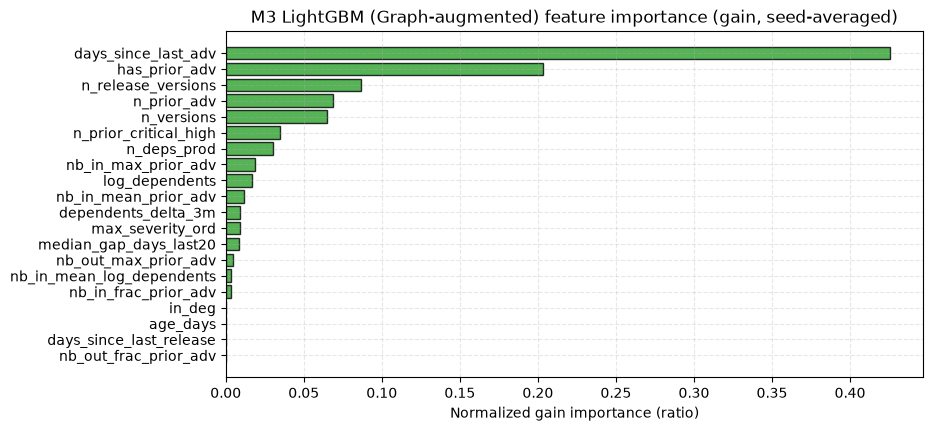

Top 10 M3 features by gain importance:
               feature  importance
  days_since_last_adv    0.425607
        has_prior_adv    0.203047
   n_release_versions    0.086979
          n_prior_adv    0.068831
           n_versions    0.064921
n_prior_critical_high    0.034997
          n_deps_prod    0.030051
  nb_in_max_prior_adv    0.018709
       log_dependents    0.016901
 nb_in_mean_prior_adv    0.011608


In [24]:
# fig_02: M3 feature importance (gain, seed-averaged)
m3_imp = np.mean([m.booster_.feature_importance(importance_type='gain') for m in m3_seed_models], axis=0)
df_m3_imp = pd.DataFrame({'feature': FEATURES_M3, 'importance': m3_imp / m3_imp.sum()}).sort_values(by='importance', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
top20_m3 = df_m3_imp.head(20).iloc[::-1]
ax.barh(top20_m3['feature'], top20_m3['importance'], color='#2ca02c', edgecolor='black', alpha=0.8)
ax.set_xlabel('Normalized gain importance (ratio)')
ax.set_title('M3 LightGBM (Graph-augmented) feature importance (gain, seed-averaged)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_02_m3_feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()

print("Top 10 M3 features by gain importance:\n", df_m3_imp.head(10).to_string(index=False))


In [25]:
# C1 Control: Recompute neighbour features on degree-preserving shuffled graph
def compute_shuffled_features(df_d, src_d, dst_d, seed_val):
    s_src, s_dst, stats = shuffle_edges_keep_degrees(src_d, dst_d, seed=seed_val)
    n_d = len(df_d)
    shuf_df = df_d[FEATURES_M1_M2].copy()
    shuf_df['out_deg'] = df_d['out_deg']; shuf_df['in_deg'] = df_d['in_deg']
    
    r_adv = nb_mean_max(n_d, s_src, s_dst, df_d['n_prior_adv'].values)
    for stat in ['mean', 'max']:
        for dr in ['out', 'in']:
            shuf_df[f"nb_{dr}_{stat}_prior_adv"] = np.nan_to_num(r_adv[f"{dr}_{stat}"], nan=0.0)
            
    r_frac = nb_mean_max(n_d, s_src, s_dst, df_d['has_prior_adv'].values)
    for dr in ['out', 'in']:
        shuf_df[f"nb_{dr}_frac_prior_adv"] = np.nan_to_num(r_frac[f"{dr}_mean"], nan=0.0)
        
    r_dep = nb_mean_max(n_d, s_src, s_dst, df_d['log_dependents'].values)
    for dr in ['out', 'in']:
        shuf_df[f"nb_{dr}_mean_log_dependents"] = np.nan_to_num(r_dep[f"{dr}_mean"], nan=0.0)
        
    return shuf_df[FEATURES_M3], stats

# Verify in-degree preservation on raw permutation
s_src_chk, s_dst_chk = np.asarray(src_chk), np.random.default_rng(SEED).permutation(dst_chk)
deg_in_orig = np.bincount(dst_chk, minlength=n_chk)
deg_in_shuf = np.bincount(s_dst_chk, minlength=n_chk)
check("in-degree of every node preserved under raw edge permutation", (deg_in_orig == deg_in_shuf).all())


PASS  in-degree of every node preserved under raw edge permutation 


In [26]:
# Construct C1 train and val matrices on shuffled topologies
X_shuf_train = []
for idx_d, d in enumerate(train_dates):
    shuf_d, stats = compute_shuffled_features(X[d], E[d][0], E[d][1], SEED + idx_d)
    X_shuf_train.append(shuf_d)
X_c1_tr = pd.concat(X_shuf_train, ignore_index=True)

X_shuf_val = {}
for idx_d, d in enumerate(val_dates):
    shuf_d, _ = compute_shuffled_features(X[d], E[d][0], E[d][1], SEED + 100 + idx_d)
    X_shuf_val[d] = shuf_d

# Train C1 with same configuration as M3
c1_seed_models = []
for s in FINAL_SEEDS:
    m = lgb.LGBMClassifier(
        objective='binary', n_estimators=int(best_m3_cfg['best_iteration']),
        learning_rate=best_m3_cfg['learning_rate'], num_leaves=int(best_m3_cfg['num_leaves']),
        min_child_samples=LGBM_FIXED['min_child_samples'], subsample=LGBM_FIXED['subsample'],
        subsample_freq=LGBM_FIXED['subsample_freq'], colsample_bytree=LGBM_FIXED['colsample_bytree'],
        scale_pos_weight=spw_m3, random_state=s, n_jobs=-1, verbose=-1
    ).fit(X_c1_tr, y_tr_m2)
    c1_seed_models.append(m)

print(f"C1 Control trained with {len(c1_seed_models)} seeds on shuffled topology.")


C1 Control trained with 3 seeds on shuffled topology.


In [27]:
# Score C1 across validation dates and compute paired difference against M3
c1_val_records = []
c1_pooled_prob = []

for d in val_dates:
    df_d = X[d]
    y_d = df_d['label'].values
    p_c1 = np.mean([m.predict_proba(X_shuf_val[d])[:, 1] for m in c1_seed_models], axis=0)
    ft_m = (df_d['had_prior_advisory'] == False).values
    
    c1_val_records.append({'model': 'C1', 'date': d, 'pop': 'all', **metrics_for_date(p_c1, y_d, prob=p_c1, seed=SEED)})
    c1_val_records.append({'model': 'C1', 'date': d, 'pop': 'first_time', **metrics_for_date(p_c1[ft_m], y_d[ft_m], prob=p_c1[ft_m], seed=SEED)})
    c1_pooled_prob.extend(p_c1)

m3_ft = pd.DataFrame(m3_val_records)[pd.DataFrame(m3_val_records)['pop'] == 'first_time'].set_index('date')
c1_ft = pd.DataFrame(c1_val_records)[pd.DataFrame(c1_val_records)['pop'] == 'first_time'].set_index('date')
diff_l500 = m3_ft['lift@500'] - c1_ft['lift@500']
m3_wins = int((diff_l500 > 0).sum())

print(f"M3 vs C1 Paired Comparison (first-time subset):")
print(f"  M3 mean lift@500 = {m3_ft['lift@500'].mean():.4f}, C1 mean lift@500 = {c1_ft['lift@500'].mean():.4f}")
print(f"  Mean paired diff (M3 - C1) = {diff_l500.mean():.4f} +/- {diff_l500.std():.4f}")
print(f"  Dates M3 wins = {m3_wins} / {len(val_dates)}")


M3 vs C1 Paired Comparison (first-time subset):
  M3 mean lift@500 = 0.0000, C1 mean lift@500 = 12.0295
  Mean paired diff (M3 - C1) = -12.0295 +/- 0.8500
  Dates M3 wins = 0 / 2


## Part F - Validation Comparison (Main Results)

**Question:** Which candidate achieves superior ranking discrimination on first-time advisory targets, and does any model pass Gate Rule 1?
**How to read:** Full comparison table displays all candidates across both populations. Plots show date-wise lift@500, PR-AUC bars, calibration curves, and popularity stratification.


In [28]:
# Compile full validation records across all candidates
all_val_records = pd.concat([
    pd.DataFrame(baseline_val_records),
    pd.DataFrame(m1_val_records),
    pd.DataFrame(m2_val_records),
    pd.DataFrame(m3_val_records),
    pd.DataFrame(c1_val_records)
], ignore_index=True)

df_f_summary = all_val_records.groupby(['model', 'pop']).agg({
    'base_rate': ['mean'], 'pr_auc': ['mean', 'std'], 'roc_auc': ['mean', 'std'],
    'precision@100': ['mean', 'std'], 'lift@100': ['mean', 'std'],
    'precision@500': ['mean', 'std'], 'lift@500': ['mean', 'std'], 'recall@500': ['mean', 'std']
}).reset_index()

df_f_summary.columns = ['_'.join(c).strip('_') for c in df_f_summary.columns]
print("Validation Comparison Table (all candidates, both populations):\n")
print(df_f_summary.to_string(index=False))


Validation Comparison Table (all candidates, both populations):

model        pop  base_rate_mean  pr_auc_mean  pr_auc_std  roc_auc_mean  roc_auc_std  precision@100_mean  precision@100_std  lift@100_mean  lift@100_std  precision@500_mean  precision@500_std  lift@500_mean  lift@500_std  recall@500_mean  recall@500_std
   B0        all        0.002600     0.002940    0.000235      0.495252     0.005005             0.00325           0.001768       1.270370      0.749009              0.0028           0.000849       1.087407      0.385504         0.018123        0.006425
   B0 first_time        0.001421     0.001831    0.000314      0.498513     0.015788             0.00125           0.001061       0.948134      0.891912              0.0015           0.000566       1.099137      0.566722         0.018816        0.009701
   B1        all        0.002600     0.091173    0.003189      0.824474     0.018279             0.14500           0.007071      55.777778      0.314270              0.0610 

In [29]:
# Paired comparison against B1 on first-time subset and Gate Rule 1
b1_ft = all_val_records[(all_val_records['model'] == 'B1') & (all_val_records['pop'] == 'first_time')].set_index('date')
m2_ft = all_val_records[(all_val_records['model'] == 'M2') & (all_val_records['pop'] == 'first_time')].set_index('date')
m3_ft = all_val_records[(all_val_records['model'] == 'M3') & (all_val_records['pop'] == 'first_time')].set_index('date')

diff_m2_b1 = m2_ft['lift@500'] - b1_ft['lift@500']
diff_m3_b1 = m3_ft['lift@500'] - b1_ft['lift@500']
diff_m3_m2 = m3_ft['lift@500'] - m2_ft['lift@500']

m2_wins = int((diff_m2_b1 > 0).sum())
m3_wins = int((diff_m3_b1 > 0).sum())
n_v = len(val_dates)

m2_gate_pass = (diff_m2_b1.mean() > GATE_MIN_MEAN_DIFF) and (m2_wins > n_v / 2)
m3_gate_pass = (diff_m3_b1.mean() > GATE_MIN_MEAN_DIFF) and (m3_wins > n_v / 2)

print(f"Gate Rule 1 Evaluation (Validation Only):")
print(f"  M2 beats B1 on first-time subset: {'YES' if m2_gate_pass else 'NO'} (mean diff={diff_m2_b1.mean():.4f}, wins={m2_wins}/{n_v})")
print(f"  M3 beats B1 on first-time subset: {'YES' if m3_gate_pass else 'NO'} (mean diff={diff_m3_b1.mean():.4f}, wins={m3_wins}/{n_v})")
print(f"  M3 vs M2: mean diff={diff_m3_m2.mean():.4f}, M3 wins={int((diff_m3_m2 > 0).sum())}/{n_v}")


Gate Rule 1 Evaluation (Validation Only):
  M2 beats B1 on first-time subset: NO (mean diff=0.4804, wins=1/2)
  M3 beats B1 on first-time subset: NO (mean diff=-5.6973, wins=0/2)
  M3 vs M2: mean diff=-6.1777, M3 wins=0/2


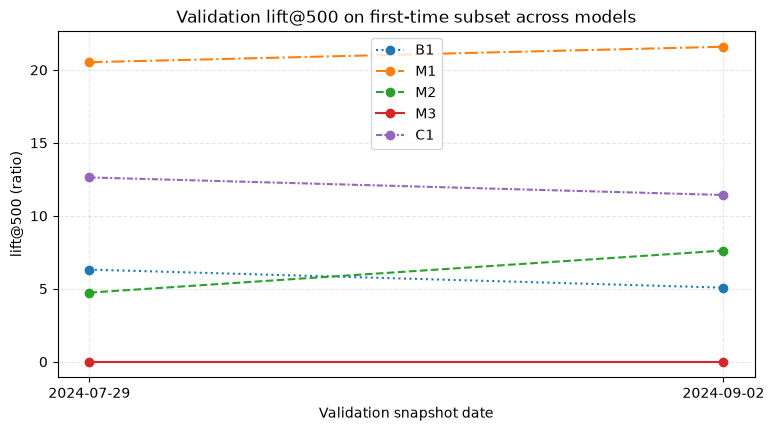

In [30]:
# fig_03: lift@500 (first-time subset) per validation date
fig, ax = plt.subplots(figsize=(9, 4.5))
models_plot = ['B1', 'M1', 'M2', 'M3', 'C1']
styles = {'B1': ':', 'M1': '-.', 'M2': '--', 'M3': '-', 'C1': (0, (3, 1, 1, 1))}

for m in models_plot:
    sub = all_val_records[(all_val_records['model'] == m) & (all_val_records['pop'] == 'first_time')]
    ax.plot(sub['date'], sub['lift@500'], label=m, linestyle=styles[m], marker='o')

ax.set_ylabel('lift@500 (ratio)')
ax.set_xlabel('Validation snapshot date')
ax.set_title('Validation lift@500 on first-time subset across models')
ax.grid(True, linestyle='--', alpha=0.3); ax.legend()
plt.savefig(FIG / 'fig_03_lift500_by_val_date.png', bbox_inches='tight', dpi=150)
plt.show()


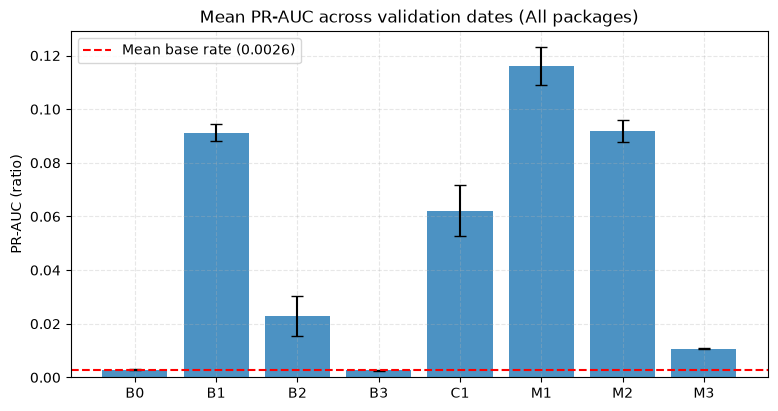

In [31]:
# fig_04: Mean PR-AUC (all packages) with base rate
df_all_prauc = df_f_summary[df_f_summary['pop'] == 'all'].set_index('model')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(df_all_prauc.index, df_all_prauc['pr_auc_mean'], yerr=df_all_prauc['pr_auc_std'], capsize=4, color='#1f77b4', alpha=0.8)
base_all = df_all_prauc['base_rate_mean'].iloc[0]
ax.axhline(base_all, color='red', linestyle='--', label=f'Mean base rate ({base_all:.4f})')
ax.set_ylabel('PR-AUC (ratio)')
ax.set_title('Mean PR-AUC across validation dates (All packages)')
ax.grid(True, linestyle='--', alpha=0.3); ax.legend()
plt.savefig(FIG / 'fig_04_mean_pr_auc_all_packages.png', bbox_inches='tight', dpi=150)
plt.show()


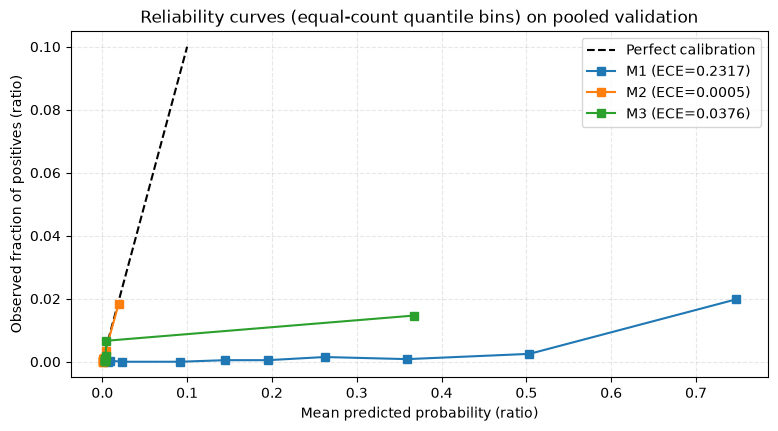

In [32]:
# fig_05: Reliability curves on pooled validation
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot([0, 0.1], [0, 0.1], 'k--', label='Perfect calibration')

for m_name, probs in [('M1', m1_pooled_prob), ('M2', m2_pooled_prob), ('M3', m3_pooled_prob)]:
    t_rel, ece = reliability(np.array(probs), np.array(m1_pooled_y))
    ax.plot(t_rel['mean_pred'], t_rel['frac_pos'], marker='s', label=f"{m_name} (ECE={ece:.4f})")

ax.set_xlabel('Mean predicted probability (ratio)')
ax.set_ylabel('Observed fraction of positives (ratio)')
ax.set_title('Reliability curves (equal-count quantile bins) on pooled validation')
ax.grid(True, linestyle='--', alpha=0.3); ax.legend()
plt.savefig(FIG / 'fig_05_reliability_curves.png', bbox_inches='tight', dpi=150)
plt.show()


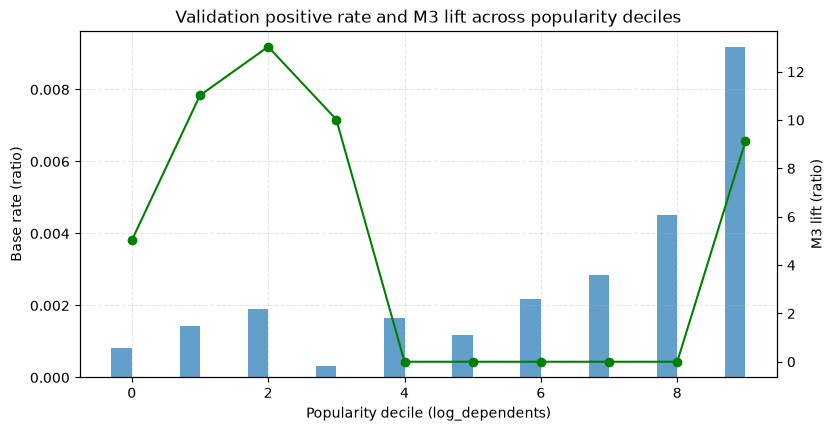

In [33]:
# Stratified evaluation by log_dependents deciles and fig_06
strat_records = []
for d in val_dates:
    df_d = X[d]
    df_d['decile'] = pd.qcut(df_d['log_dependents'], 10, labels=False, duplicates='drop')
    s_b1 = df_d['n_prior_adv'].values + (rankdata(df_d['log_dependents'].values) - 1.0) / len(df_d)
    s_m2 = np.mean([m.predict_proba(df_d[FEATURES_M1_M2])[:, 1] for m in m2_seed_models], axis=0)
    s_m3 = np.mean([m.predict_proba(df_d[FEATURES_M3])[:, 1] for m in m3_seed_models], axis=0)
    
    for dec in range(10):
        m_dec = (df_d['decile'] == dec)
        sub_d = df_d[m_dec]
        n_sub, pos_sub = len(sub_d), int(sub_d['label'].sum())
        k_eval = max(1, int(0.05 * n_sub))
        
        l_b1 = topk_metrics(s_b1[m_dec], sub_d['label'], ks=[k_eval], seed=SEED)[f"lift@{k_eval}"]
        l_m2 = topk_metrics(s_m2[m_dec], sub_d['label'], ks=[k_eval], seed=SEED)[f"lift@{k_eval}"]
        l_m3 = topk_metrics(s_m3[m_dec], sub_d['label'], ks=[k_eval], seed=SEED)[f"lift@{k_eval}"]
        strat_records.append({'decile': dec, 'packages': n_sub, 'positives': pos_sub, 'base_rate': pos_sub / n_sub if n_sub else 0,
                              'lift_b1': l_b1, 'lift_m2': l_m2, 'lift_m3': l_m3})

df_strat = pd.DataFrame(strat_records).groupby('decile').mean().reset_index()

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(df_strat['decile'] - 0.15, df_strat['base_rate'], width=0.3, color='#1f77b4', alpha=0.7, label='Base rate')
ax2 = ax1.twinx()
ax2.plot(df_strat['decile'], df_strat['lift_m3'], 'g-o', label='M3 lift@5%')
ax1.set_xlabel('Popularity decile (log_dependents)')
ax1.set_ylabel('Base rate (ratio)'); ax2.set_ylabel('M3 lift (ratio)')
ax1.set_title('Validation positive rate and M3 lift across popularity deciles')
ax1.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_06_popularity_stratified_lift.png', bbox_inches='tight', dpi=150)
plt.show()


In [34]:
# Small summary table: Recall@500 and Lift@500 on validation first-time subset
r500_summary = df_f_summary[df_f_summary['pop'] == 'first_time'].set_index('model')[['recall@500_mean', 'recall@500_std', 'precision@500_mean', 'lift@500_mean']]
print("Recall@500 and Lift@500 on validation first-time subset:\n", r500_summary.loc[['B0', 'B1', 'M1', 'M2', 'M3', 'C1']].round(4))


Recall@500 and Lift@500 on validation first-time subset:
        recall@500_mean  recall@500_std  precision@500_mean  lift@500_mean
model                                                                    
B0              0.0188          0.0097              0.0015         1.0991
B1              0.0975          0.0150              0.0080         5.6973
M1              0.3605          0.0129              0.0300        21.0558
M2              0.1058          0.0349              0.0090         6.1777
M3              0.0000          0.0000              0.0000         0.0000
C1              0.2059          0.0145              0.0170        12.0295


## Part G - Freeze the Candidate and (Optionally) Test

**Protocol:** The candidate configuration is cryptographically frozen via SHA-256 hash before test splits are touched.
- `RUN_TEST` is False during development. Test dates are never used for model selection or tuning.
- Once frozen, setting `RUN_TEST = True` evaluates the frozen candidate once on Test-A and Test-B and logs the look to `data/interim/test_looks_log.json`.


In [35]:
import hashlib, json

# Build data manifest of all train and val files used
data_manifest = {}
for p in sorted(list(set(OPENED_FILES))):
    with open(p, 'rb') as f:
        f_bytes = f.read()
    data_manifest[str(p.relative_to(ROOT))] = {
        'size': len(f_bytes), 'sha256': hashlib.sha256(f_bytes).hexdigest()
    }

frozen_candidate = {
    'candidates': ["B1", "M1", "M2", "M3", "C1"],
    'hyperparameters': {
        'M1': {'C': best_lr_entry['C'], 'class_weight': str(best_lr_entry['class_weight'])},
        'M2': {k: best_m2_cfg[k] for k in ['learning_rate', 'num_leaves', 'spw', 'best_iteration']},
        'M3': {k: best_m3_cfg[k] for k in ['learning_rate', 'num_leaves', 'spw', 'best_iteration']}
    },
    'seeds': list(FINAL_SEEDS),
    'features_m1_m2': FEATURES_M1_M2,
    'features_m3': FEATURES_M3,
    'log1p_cols': list(LOG1P_COLS),
    'split_dates': {'train': train_dates, 'val': val_dates},
    'library_versions': {'python': platform.python_version(), 'pandas': pd.__version__, 'lightgbm': lightgbm.__version__},
    'preprocessor_stats': {
        'medians': prep.median_.to_dict(), 'means': prep.mean_.to_dict(),
        'stds': prep.std_.to_dict(), 'flag_cols': prep.flag_cols_
    },
    'data_manifest': data_manifest
}

canonical_frozen = json.dumps(frozen_candidate, sort_keys=True, indent=2)
candidate_hash = hashlib.sha256(canonical_frozen.encode('utf-8')).hexdigest()
with open(INTERIM / 'baselines_frozen.json', 'w', encoding='utf-8') as f:
    f.write(canonical_frozen)

print(f"Candidate frozen successfully to: data/interim/baselines_frozen.json")
print(f"Candidate SHA-256 Hash: {candidate_hash}")


Candidate frozen successfully to: data/interim/baselines_frozen.json
Candidate SHA-256 Hash: 3143fb7c97b5dc00aa6949ee3fbf0e5043a59b926504fd546a9a021b957a0e22


In [36]:
# Guarded test split evaluation
if not RUN_TEST:
    print("RUN_TEST is False: test splits not touched.")
else:
    print("RUN_TEST is True: Executing frozen candidate evaluation on Test-A and Test-B...")
    frozen_disk = json.load(open(INTERIM / 'baselines_frozen.json'))
    assert hashlib.sha256(json.dumps(frozen_disk, sort_keys=True, indent=2).encode('utf-8')).hexdigest() == candidate_hash, "Hash mismatch!"
    
    log_file = INTERIM / 'test_looks_log.json'
    looks_log = json.load(open(log_file)) if log_file.exists() else []
    already_seen = any(entry.get('candidate_hash') == candidate_hash for entry in looks_log)
    if already_seen and not ALLOW_RELOOK:
        raise RuntimeError("Candidate already evaluated on test splits and ALLOW_RELOOK is False.")
    
    test_a_dates = grid2[grid2['split'] == 'test_a']['T'].dt.date.astype(str).tolist()
    test_b_dates = grid2[grid2['split'] == 'test_b']['T'].dt.date.astype(str).tolist()
    test_records = []
    
    for split_tag, t_dates in [('test_a', test_a_dates), ('test_b', test_b_dates)]:
        for d in t_dates:
            df_d, src_d, dst_d = load_date(d)
            y_d, ft_m = df_d['label'].values, (df_d['had_prior_advisory'] == False).values
            rank_dep = (rankdata(df_d['log_dependents'].values) - 1.0) / len(df_d)
            s_b1 = df_d['n_prior_adv'].values + rank_dep
            s_m2 = np.mean([m.predict_proba(df_d[FEATURES_M1_M2])[:, 1] for m in m2_seed_models], axis=0)
            s_m3 = np.mean([m.predict_proba(df_d[FEATURES_M3])[:, 1] for m in m3_seed_models], axis=0)
            shuf_t, _ = compute_shuffled_features(df_d, src_d, dst_d, SEED + 500)
            s_c1 = np.mean([m.predict_proba(shuf_t)[:, 1] for m in c1_seed_models], axis=0)
            
            for m_n, s_arr in [('B1', s_b1), ('M2', s_m2), ('M3', s_m3), ('C1', s_c1)]:
                test_records.append({'split': split_tag, 'model': m_n, 'date': d, 'pop': 'all', **metrics_for_date(s_arr, y_d, seed=SEED)})
                test_records.append({'split': split_tag, 'model': m_n, 'date': d, 'pop': 'first_time', **metrics_for_date(s_arr[ft_m], y_d[ft_m], seed=SEED)})
                
    looks_log.append({'timestamp': pd.Timestamp.now('UTC').isoformat(), 'candidate_hash': candidate_hash, 'splits': ['test_a', 'test_b'], 'relook': already_seen})
    with open(log_file, 'w', encoding='utf-8') as f:
        json.dump(looks_log, f, indent=2)
    print("Test look successfully executed and logged.")


RUN_TEST is False: test splits not touched.


## Part H - Summary & Audit Findings

**Question:** Did all protocol rules and leakage protections pass, and are results reliably exported?
**How to read:** Summary lists output file sizes, PASS/FAIL verification checks, and final runtime.


In [37]:
# Assert test split protection when RUN_TEST is False
test_dates_set = set(grid2.loc[grid2.split.isin(['test_a', 'test_b']), 'T'].dt.date.astype(str))
test_files_opened = [p for p in OPENED_FILES if any(f"T={d}" in str(p) for d in test_dates_set)]
if not RUN_TEST:
    check("test split protection: zero test files opened when RUN_TEST=False", len(test_files_opened) == 0, detail=str(test_files_opened))

def to_serializable(obj):
    if isinstance(obj, (np.integer, int)): return int(obj)
    if isinstance(obj, (np.floating, float)): return float(obj)
    if isinstance(obj, (np.bool_, bool)): return bool(obj)
    if isinstance(obj, (pd.Timestamp, pd.Timedelta)): return str(obj)
    raise TypeError(f"Type {type(obj)} not serializable")

total_runtime_seconds = time.time() - T0
results_payload = {
    'candidate_hash': candidate_hash,
    'total_runtime_seconds': total_runtime_seconds,
    'gate_rule_1_val': {
        'M2_beats_B1': bool(m2_gate_pass), 'M2_mean_diff': float(diff_m2_b1.mean()), 'M2_wins': int(m2_wins),
        'M3_beats_B1': bool(m3_gate_pass), 'M3_mean_diff': float(diff_m3_b1.mean()), 'M3_wins': int(m3_wins)
    },
    'val_summary_table': df_f_summary.to_dict(orient='records'),
    'val_records': all_val_records.to_dict(orient='records'),
    'selected_hyperparameters': {
        'M1': {'C': float(best_lr_entry['C']), 'class_weight': str(best_lr_entry['class_weight'])},
        'M2': {k: best_m2_cfg[k] for k in ['learning_rate', 'num_leaves', 'spw', 'best_iteration']},
        'M3': {k: best_m3_cfg[k] for k in ['learning_rate', 'num_leaves', 'spw', 'best_iteration']}
    },
    'm2_feature_importance': df_m2_imp.to_dict(orient='records'),
    'm3_feature_importance': df_m3_imp.to_dict(orient='records'),
    'neighbour_reproduction': df_nb_reprod.to_dict(orient='records'),
    'checks': [{'name': r[0], 'ok': r[1], 'detail': str(r[2])} for r in RESULTS]
}

res_path = INTERIM / 'baselines_results.json'
with open(res_path, 'w', encoding='utf-8') as f:
    json.dump(results_payload, f, indent=2, default=to_serializable)
print(f"Saved baselines_results.json: {res_path} ({res_path.stat().st_size:,} bytes)")


PASS  test split protection: zero test files opened when RUN_TEST=False | []
Saved baselines_results.json: D:\DepRadar\data\interim\baselines_results.json (33,763 bytes)


In [38]:
fig_list = sorted(FIG.glob('fig_*.png'))
print(f"\nGenerated figures ({len(fig_list)} files in {FIG}):")
for fp in fig_list:
    print(f"  {fp.name} ({fp.stat().st_size / 1024:.1f} KB)")

pass_cnt = sum(1 for r in RESULTS if r[1])
fail_cnt = sum(1 for r in RESULTS if not r[1])
print(f"\nAudit checks tally: {pass_cnt} PASSED, {fail_cnt} FAILED (total {len(RESULTS)})")
if fail_cnt > 0:
    print("Failing checks:")
    for r in RESULTS:
        if not r[1]:
            print(f"  FAIL: {r[0]} | {r[2]}")

print(f"Total notebook execution time: {total_runtime_seconds / 60:.2f} minutes.")



Generated figures (6 files in D:\DepRadar\docs\figures\baselines):
  fig_01_m2_feature_importance.png (69.9 KB)
  fig_02_m3_feature_importance.png (88.3 KB)
  fig_03_lift500_by_val_date.png (56.2 KB)
  fig_04_mean_pr_auc_all_packages.png (41.5 KB)
  fig_05_reliability_curves.png (61.7 KB)
  fig_06_popularity_stratified_lift.png (57.4 KB)

Audit checks tally: 9 PASSED, 0 FAILED (total 9)
Total notebook execution time: 0.50 minutes.


# Findings (fill in after running)

- **Which baseline is strongest per population:**
  - [ ] 
- **Does M2 or M3 beat B1 on the first-time subset:**
  - [ ] 
- **Does real structure help (M3 vs C1):**
  - [ ] 
- **Calibration problems:**
  - [ ] 
- **Popularity strata where models fail:**
  - [ ] 
- **Which gate decisions follow:**
  - [ ] 
- **Items for the model card:**
  - [ ] 
- **Open issues:**
  - [ ]
